# Final results and presentation charts
Requires the final 1% experiment outputs from notebook 02. It fails visibly if they are absent; it never relabels historical results as final.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
DATA = Path('dataset')
assert DATA.exists(), 'Run from the submission directory'
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top':False, 'axes.spines.right':False})


,portfolio,active_sharpe,realized_TE,max_predicted_TE
0,bayesian_active,1.028096,0.013173,0.01
1,bayesian_long_only,0.884192,0.011968,0.01
2,dmd_standalone_active,0.999628,0.013159,0.01
3,dmd_standalone_long_only,0.735455,0.012005,0.01
4,equal_weight_active,1.058436,0.013241,0.01
5,inflation_standalone_active,0.254573,0.013670,0.01
6,inflation_standalone_long_only,0.128722,0.011495,0.01
7,original_dmd_matched_active,1.002518,0.013165,0.01
8,original_dmd_matched_long_only,0.736261,0.012017,0.01
9,ridge_1260_p2.5_active,1.001420,0.013146,0.01


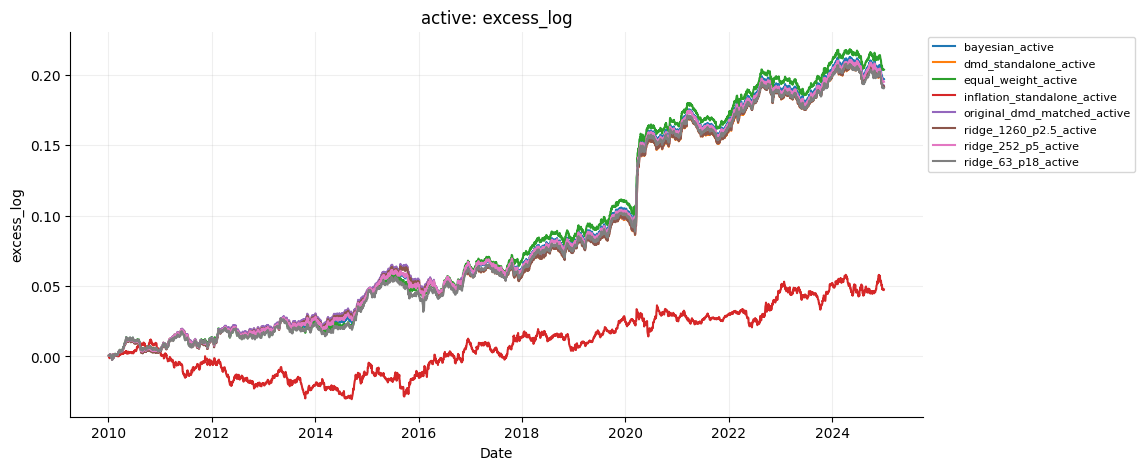

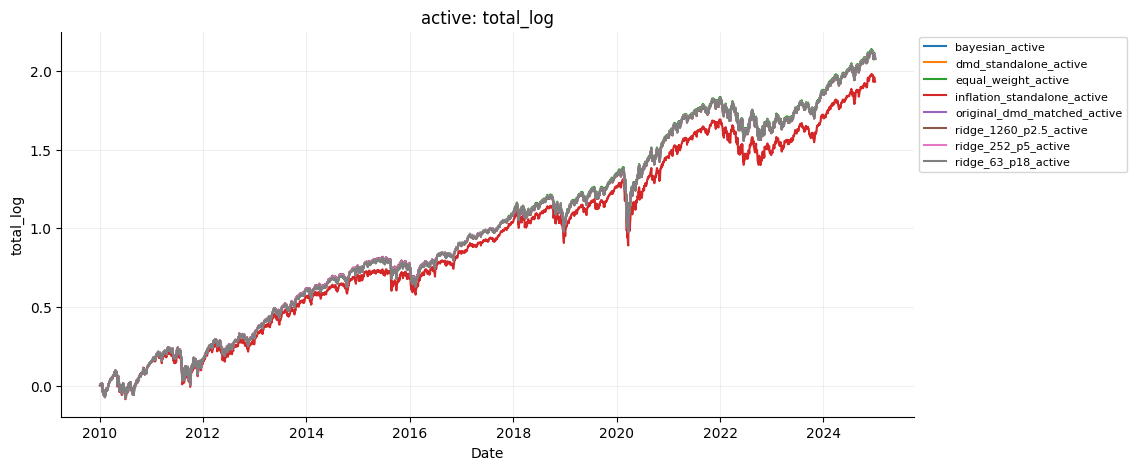

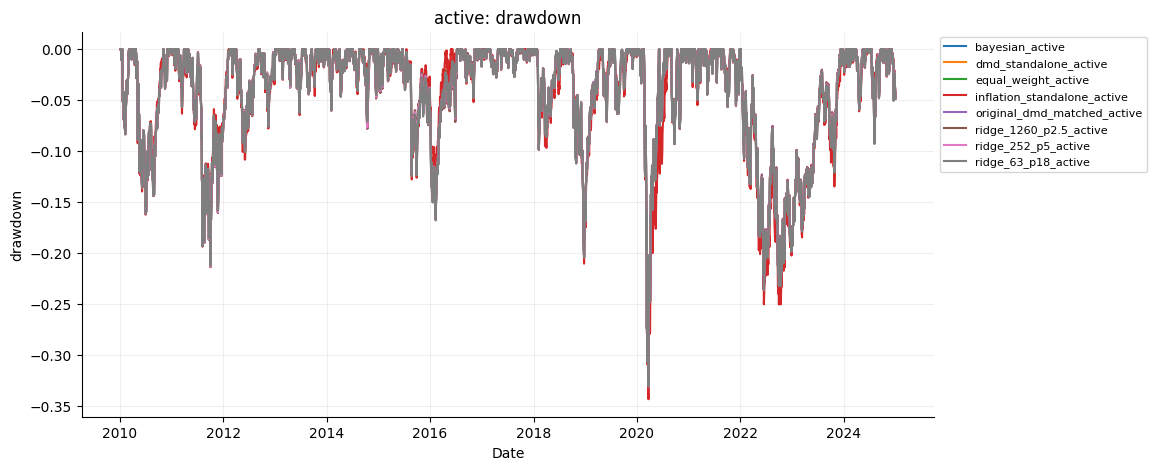

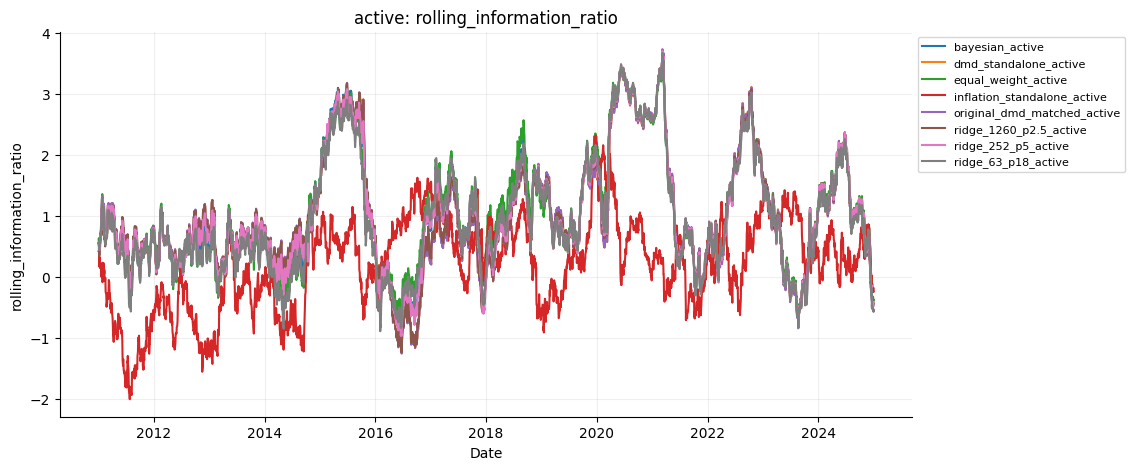

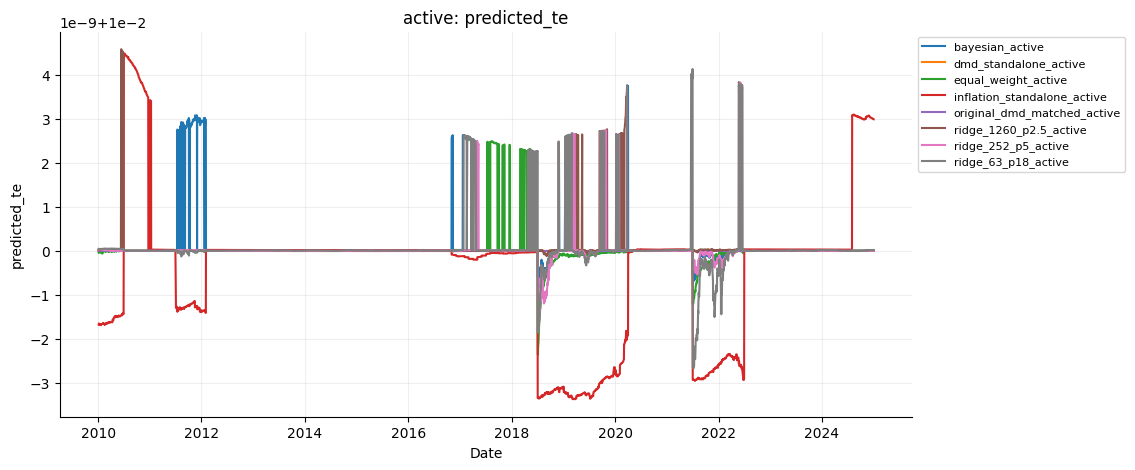

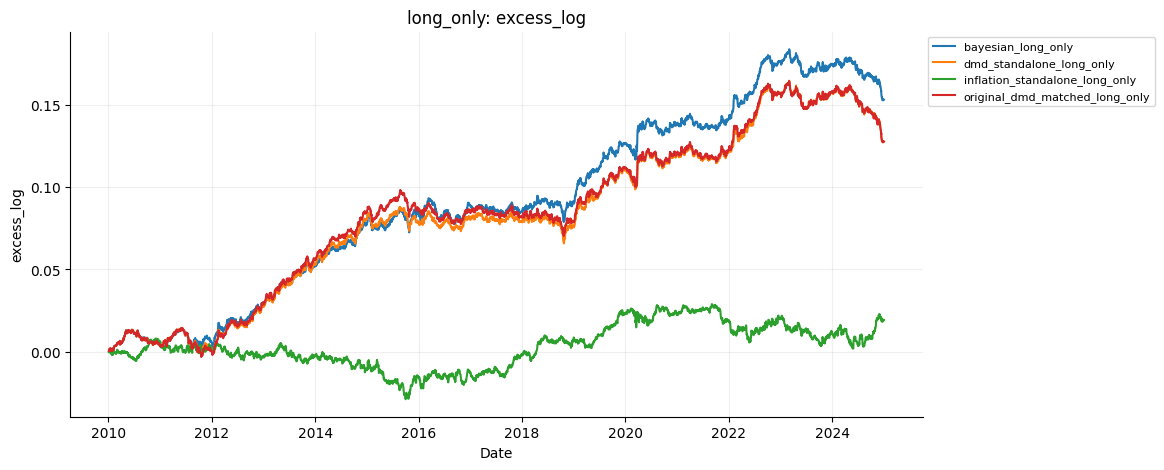

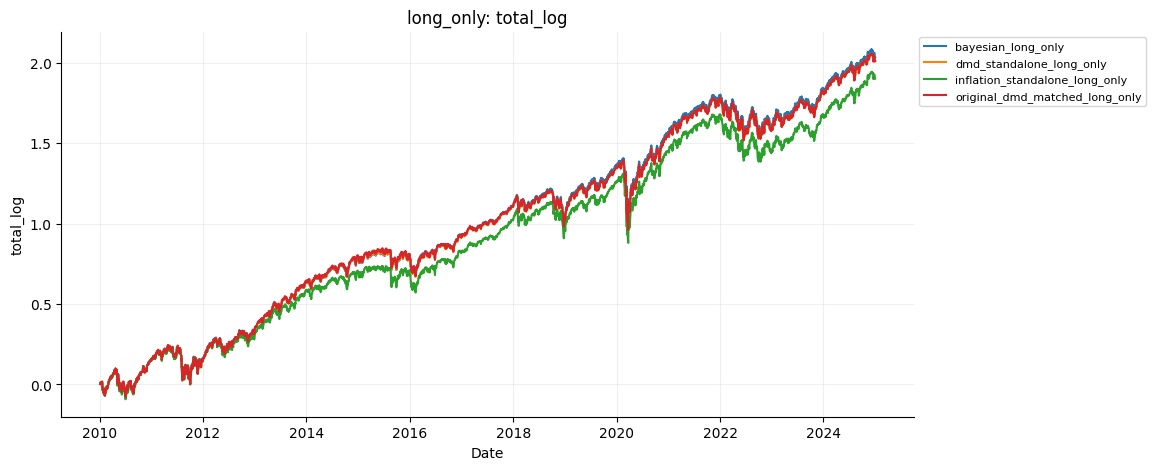

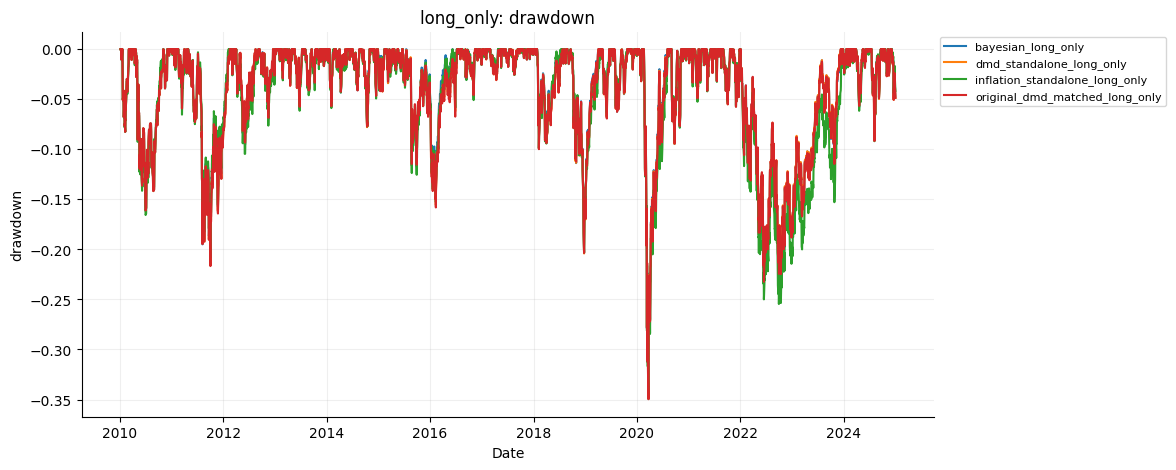

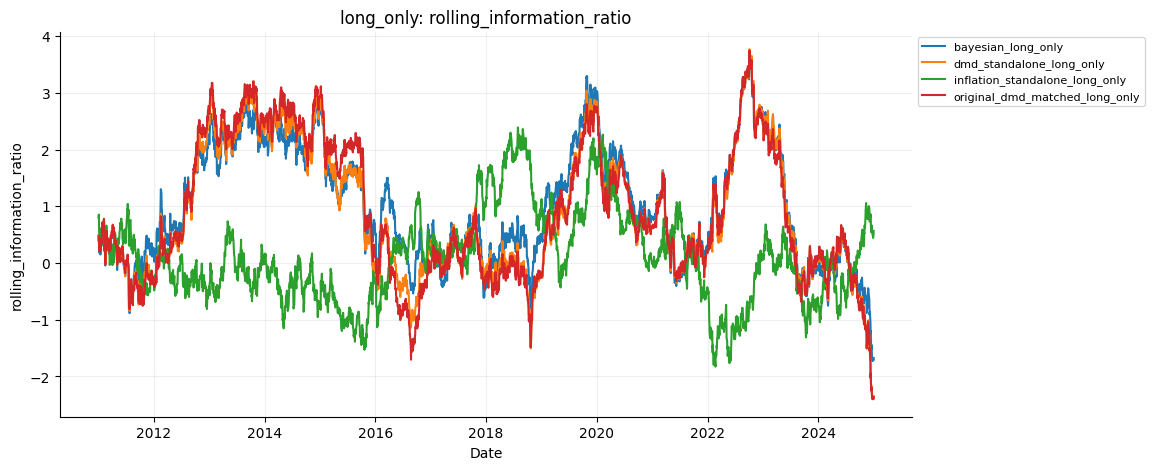

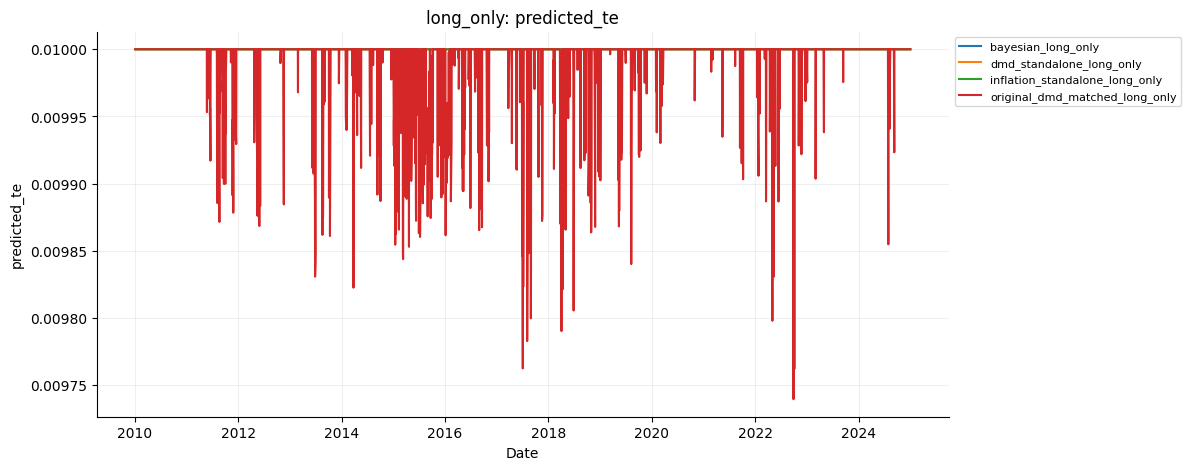

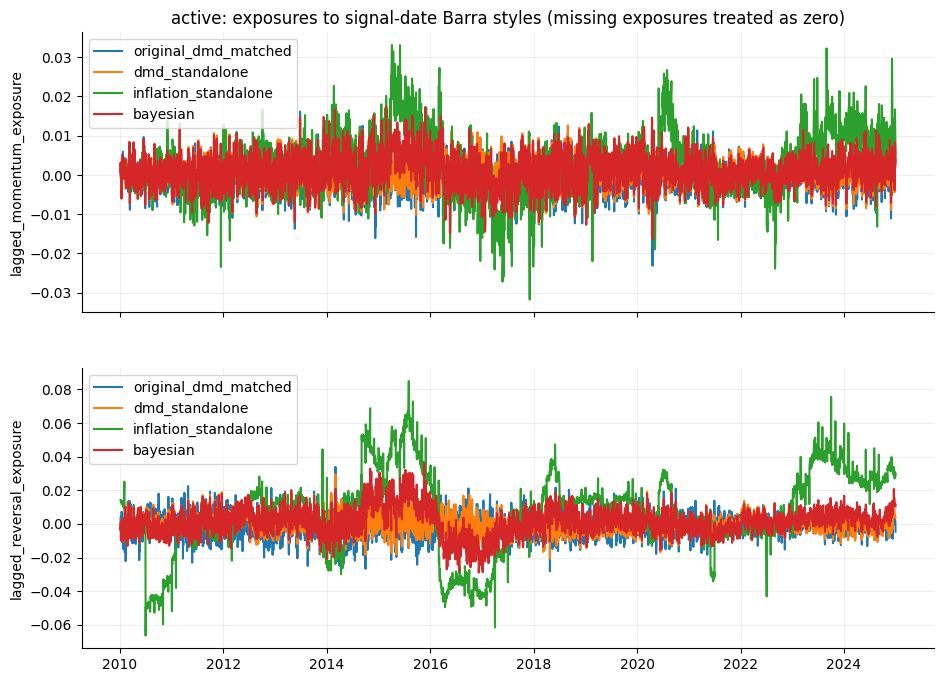

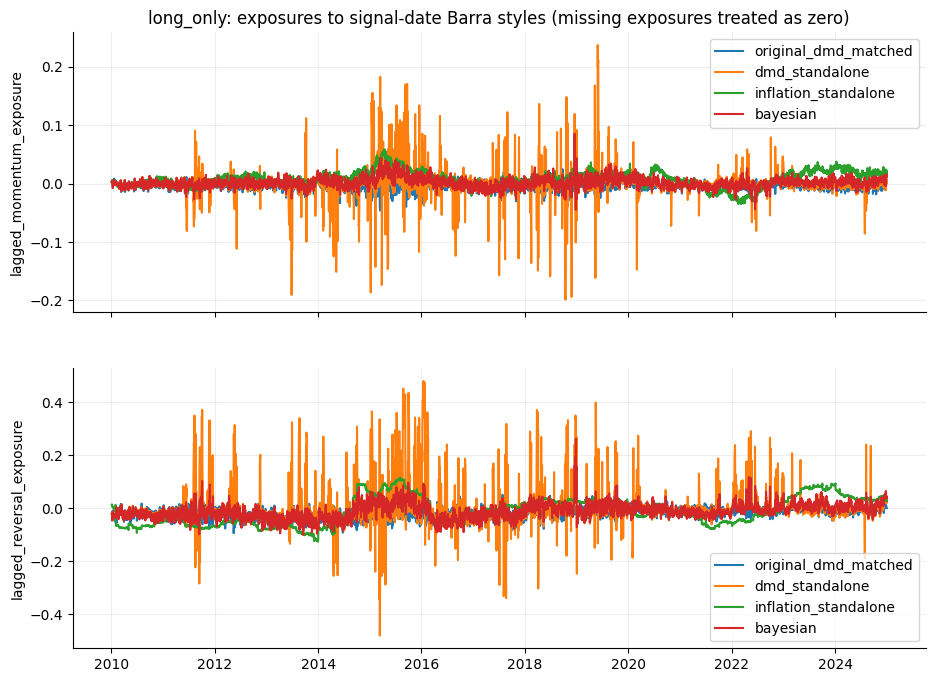

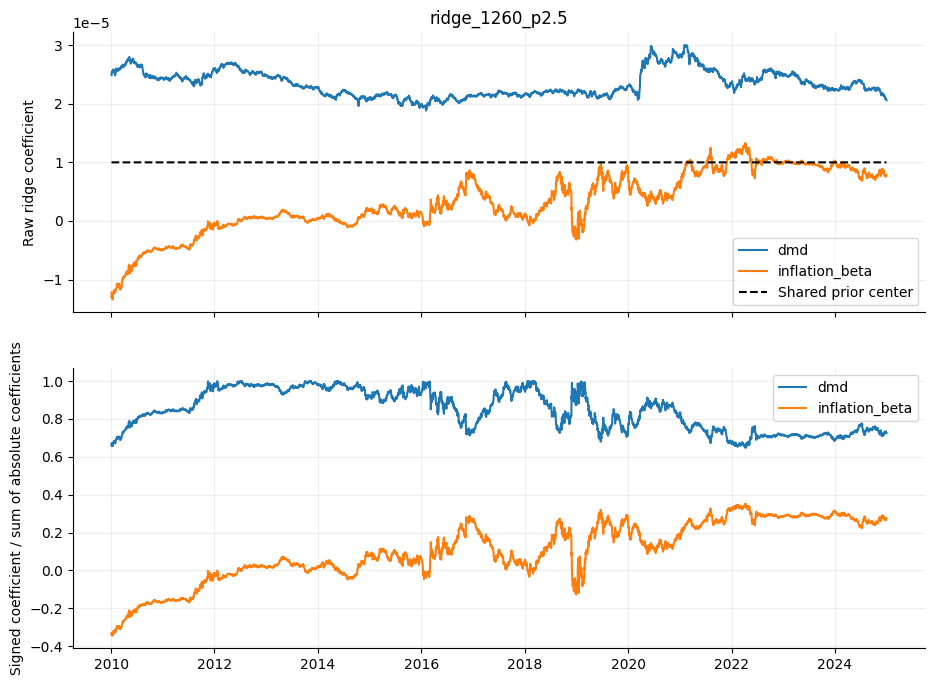

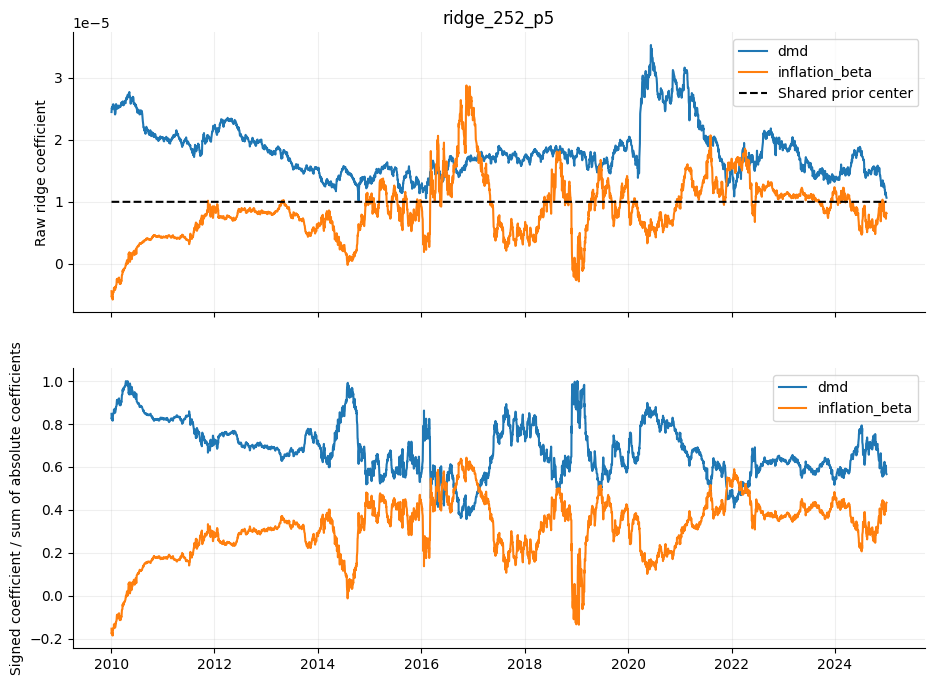

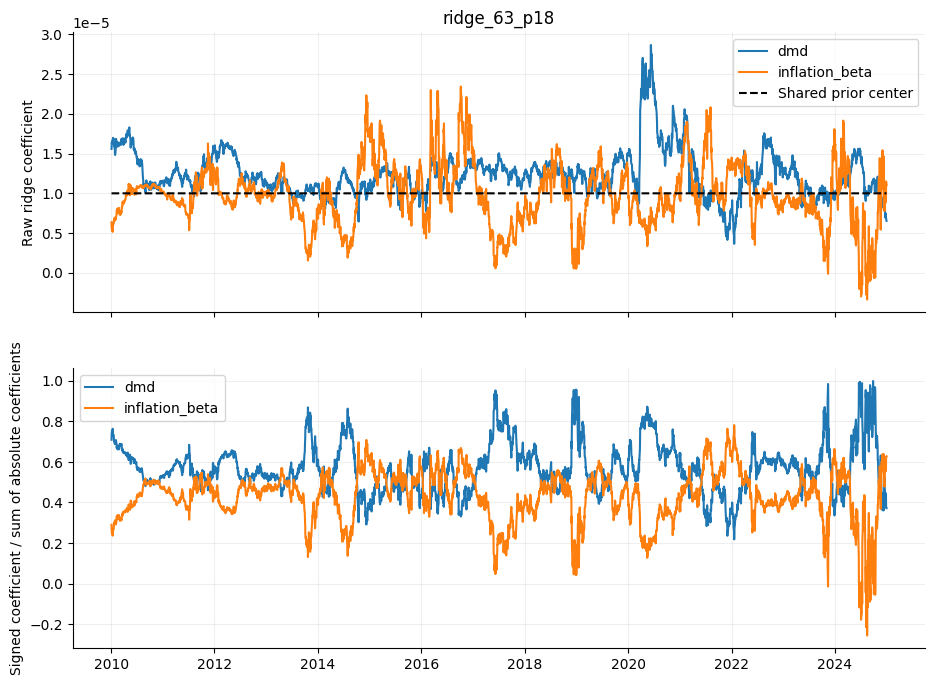

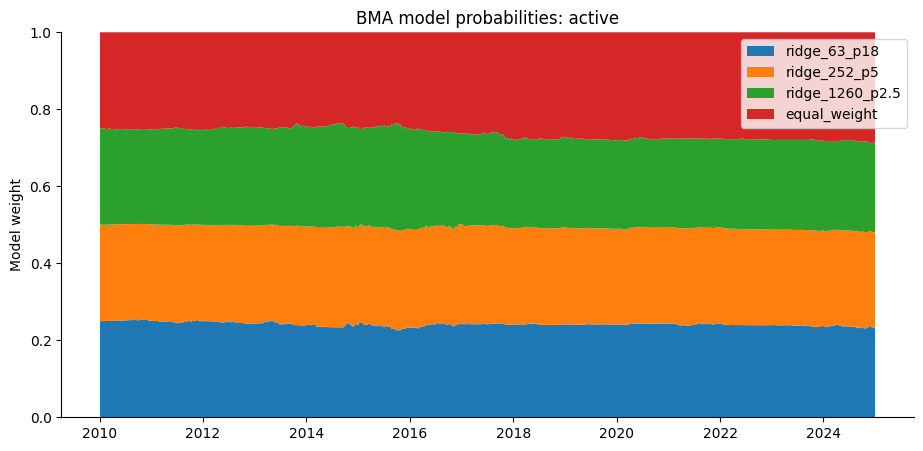

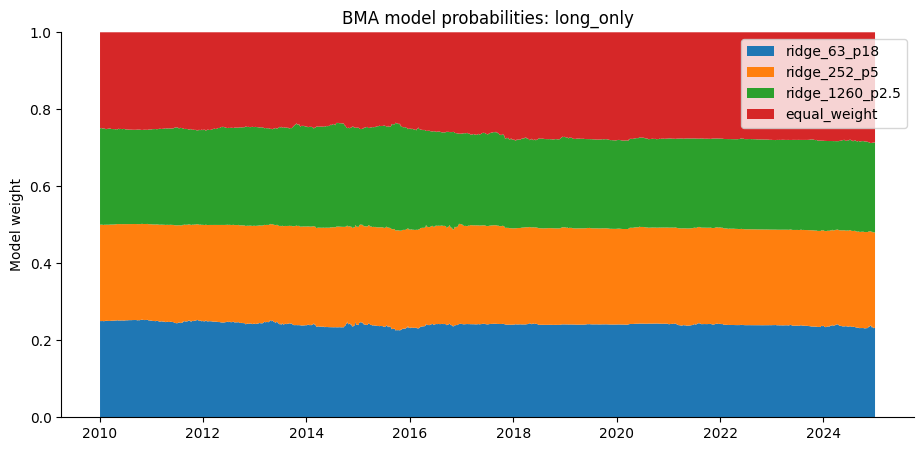

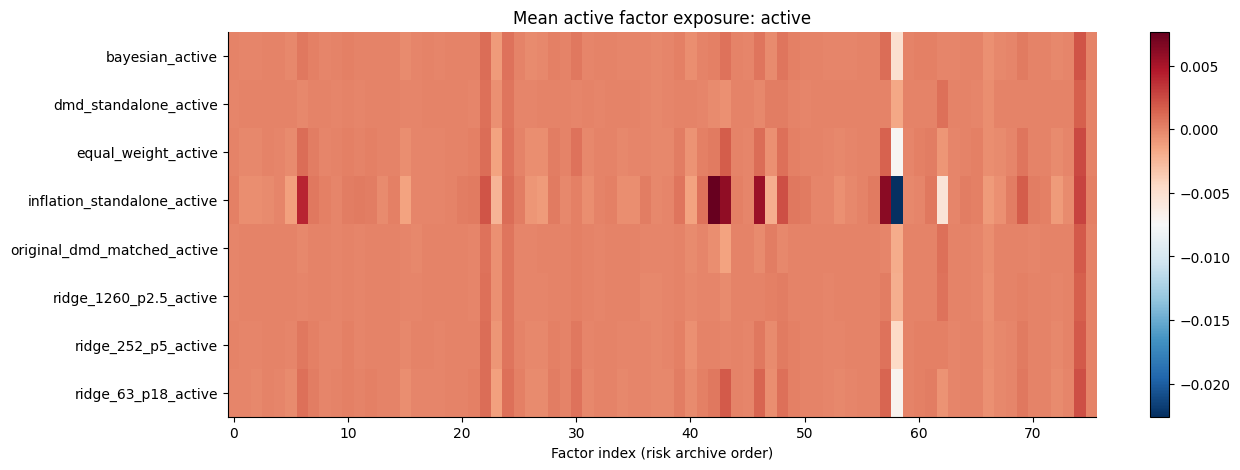

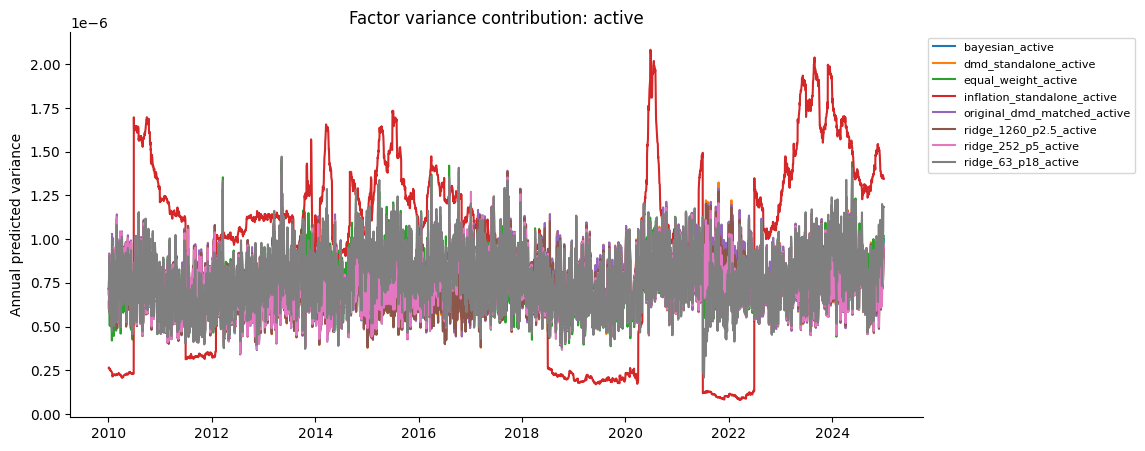

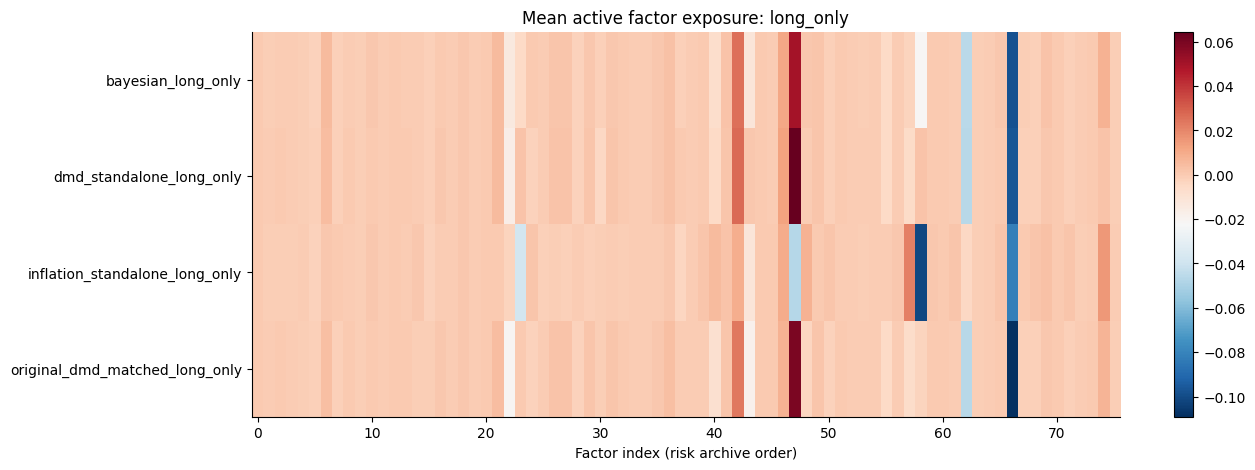

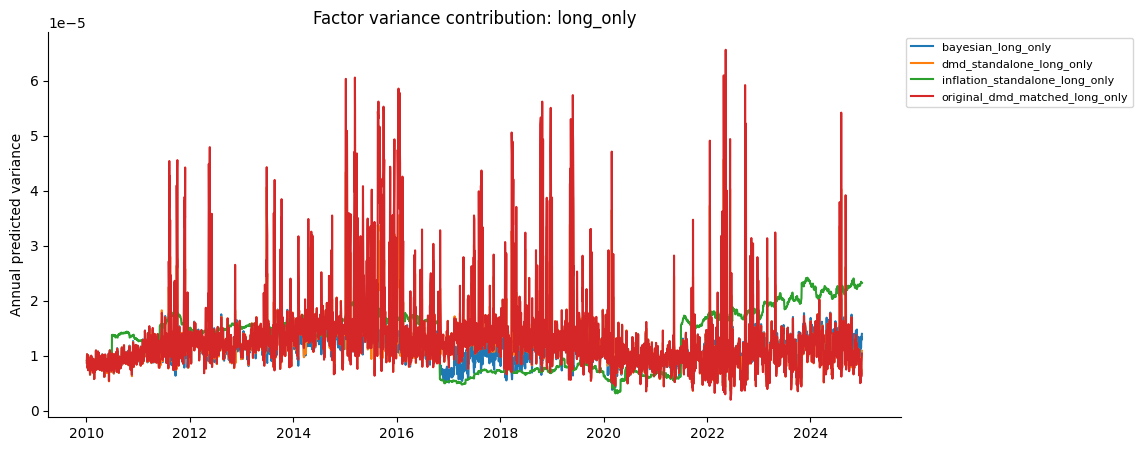

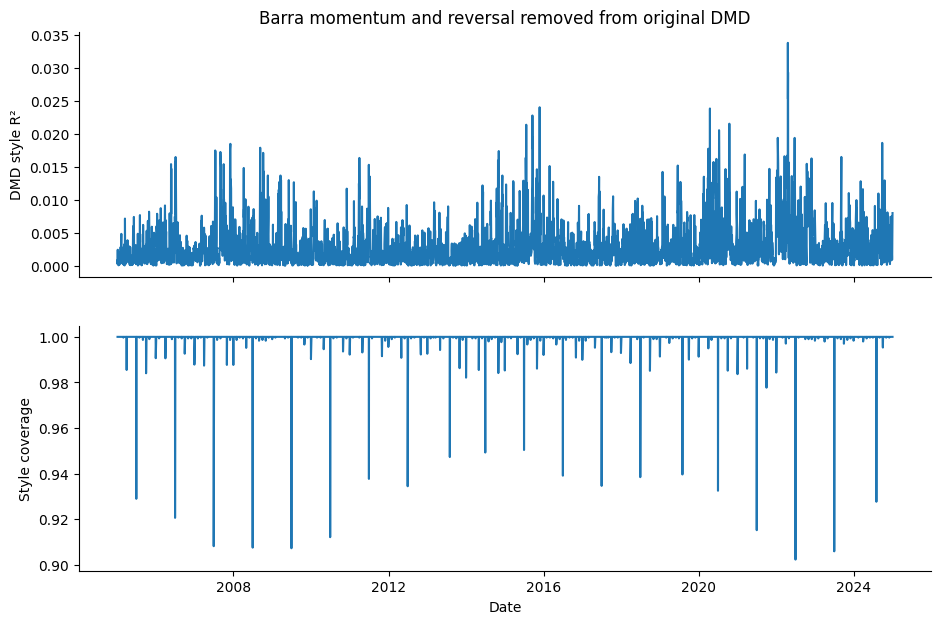

In [2]:
r=pd.read_parquet(DATA/'final_returns.parquet').sort_values('date')
c=pd.read_parquet(DATA/'final_coefficients.parquet').sort_values('date')
w=pd.read_parquet(DATA/'final_model_weights.parquet').sort_values('date')
f=pd.read_parquet(DATA/'final_factor_exposures.parquet')
assert r.predicted_te.max()<=.010001 and r.active_beta.abs().max()<1e-5
assert np.allclose(r.total_investment,1,atol=1e-5)
assert r[r.portfolio.str.endswith('_long_only')].minimum_total_weight.min()>-1e-6
metrics=[]
for name,g in r.groupby('portfolio'):
    metrics.append({'portfolio':name,'active_sharpe':np.sqrt(252)*g.active_return.mean()/g.active_return.std(),'realized_TE':np.sqrt(252)*g.active_return.std(),'max_predicted_TE':g.predicted_te.max()})
display(pd.DataFrame(metrics))
for variant in ['active','long_only']:
    sub=r[r.portfolio.str.endswith('_'+variant)]
    for kind in ['excess_log','total_log','drawdown','rolling_information_ratio','predicted_te']:
        fig,ax=plt.subplots()
        for name,g in sub.groupby('portfolio'):
            log=np.log1p(g.portfolio_return).cumsum()
            values={'excess_log':log-np.log1p(g.benchmark_return).cumsum(),'total_log':log,'drawdown':np.expm1(log-log.cummax()),'rolling_information_ratio':np.sqrt(252)*g.active_return.rolling(252).mean()/g.active_return.rolling(252).std(),'predicted_te':g.predicted_te}[kind]
            ax.plot(g.date,values,label=name)
        ax.set(title=f'{variant}: {kind}',xlabel='Date',ylabel=kind);ax.legend(fontsize=8,bbox_to_anchor=(1,1));ax.grid(alpha=.2);plt.show()
for variant in ['active','long_only']:
    fig,axes=plt.subplots(2,1,figsize=(11,8),sharex=True)
    for name in ['original_dmd_matched','dmd_standalone','inflation_standalone','bayesian']:
        g=r[r.portfolio==name+'_'+variant]
        for ax,col in zip(axes,['lagged_momentum_exposure','lagged_reversal_exposure']):
            ax.plot(g.date,g[col],label=name);ax.set(ylabel=col)
    axes[0].set_title(f'{variant}: exposures to signal-date Barra styles (missing exposures treated as zero)')
    for ax in axes: ax.legend();ax.grid(alpha=.2)
    plt.show()
for name,g in c.groupby('method'):
    fig,axes=plt.subplots(2,1,figsize=(11,8),sharex=True)
    for s in ['dmd','inflation_beta']:
        axes[0].plot(g.date,g[s],label=s)
        axes[1].plot(g.date,g[s]/g[['dmd','inflation_beta']].abs().sum(axis=1),label=s)
    axes[0].plot(g.date,g.center,'k--',label='Shared prior center')
    axes[0].set(title=name,ylabel='Raw ridge coefficient');axes[1].set(ylabel='Signed coefficient / sum of absolute coefficients')
    for ax in axes: ax.legend();ax.grid(alpha=.2)
    plt.show()
for variant,g in w.groupby('variant'):
    names=[x for x in g if x not in ['date','variant']]
    assert np.allclose(g[names].sum(axis=1),1)
    fig,ax=plt.subplots();ax.stackplot(g.date,*[g[n] for n in names],labels=names)
    ax.set(title=f'BMA model probabilities: {variant}',ylabel='Model weight',ylim=(0,1));ax.legend(bbox_to_anchor=(1,1));plt.show()
for variant in ['active','long_only']:
    sub=f[f.portfolio.str.endswith('_'+variant)]
    table=sub.groupby(['portfolio','factor_index']).active_exposure.mean().unstack()
    fig,ax=plt.subplots(figsize=(14,5));im=ax.imshow(table,aspect='auto',cmap='RdBu_r')
    ax.set_yticks(range(len(table)),table.index);ax.set(title=f'Mean active factor exposure: {variant}',xlabel='Factor index (risk archive order)')
    fig.colorbar(im,ax=ax);plt.show()
    fig,ax=plt.subplots()
    for name,g in sub.groupby('portfolio'):
        v=g.groupby('date').variance_contribution.sum()
        ax.plot(v.index,v,label=name)
    ax.set(title=f'Factor variance contribution: {variant}',ylabel='Annual predicted variance');ax.legend(fontsize=8,bbox_to_anchor=(1,1));plt.show()
d=pd.read_parquet(DATA/'style_diagnostics.parquet')
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
axes[0].plot(d.date,d.r2);axes[0].set(ylabel='DMD style R²',title='Barra momentum and reversal removed from original DMD')
axes[1].plot(d.date,d.coverage);axes[1].set(ylabel='Style coverage',xlabel='Date');plt.show()
